In [16]:
import sys
import math

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../..")

from notebooks.constants import Configs

In [17]:
def read_files(files):
    dfs = []

    for lf in files:
        df = pd.read_csv(lf, delimiter=',')
        dfs.append(df)

    df = pd.concat(dfs, ignore_index=True)
    df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
    df = df.ffill().bfill()

    mapa_mov = {0: 'Pick', 1: 'Place', 6: 'Park'} 
    df['movLabel'] = df['movType'].map(mapa_mov)

    # Cast Int
    df[["sub", "repID", "movID", "movType", "step"]] = df[["sub", "repID", "movID", "movType", "step"]].astype(int)

    return df

In [25]:
df = read_files(Configs.ICATER_PROCESSED_FILES)

In [26]:
REP_ID_TO_SHOW = 5
df_last_RepID = df[df["repID"] == 5]

In [27]:
MOVEMENT_TO_SHOW = "Pick"
df_last_RepID = df_last_RepID[df_last_RepID["movLabel"] == MOVEMENT_TO_SHOW]

In [28]:
MOV_ID_TO_SHOW = 1
df_last_RepID = df_last_RepID[df_last_RepID["movID"] == MOV_ID_TO_SHOW]

/tmp/ipykernel_22474/1933482823.py:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


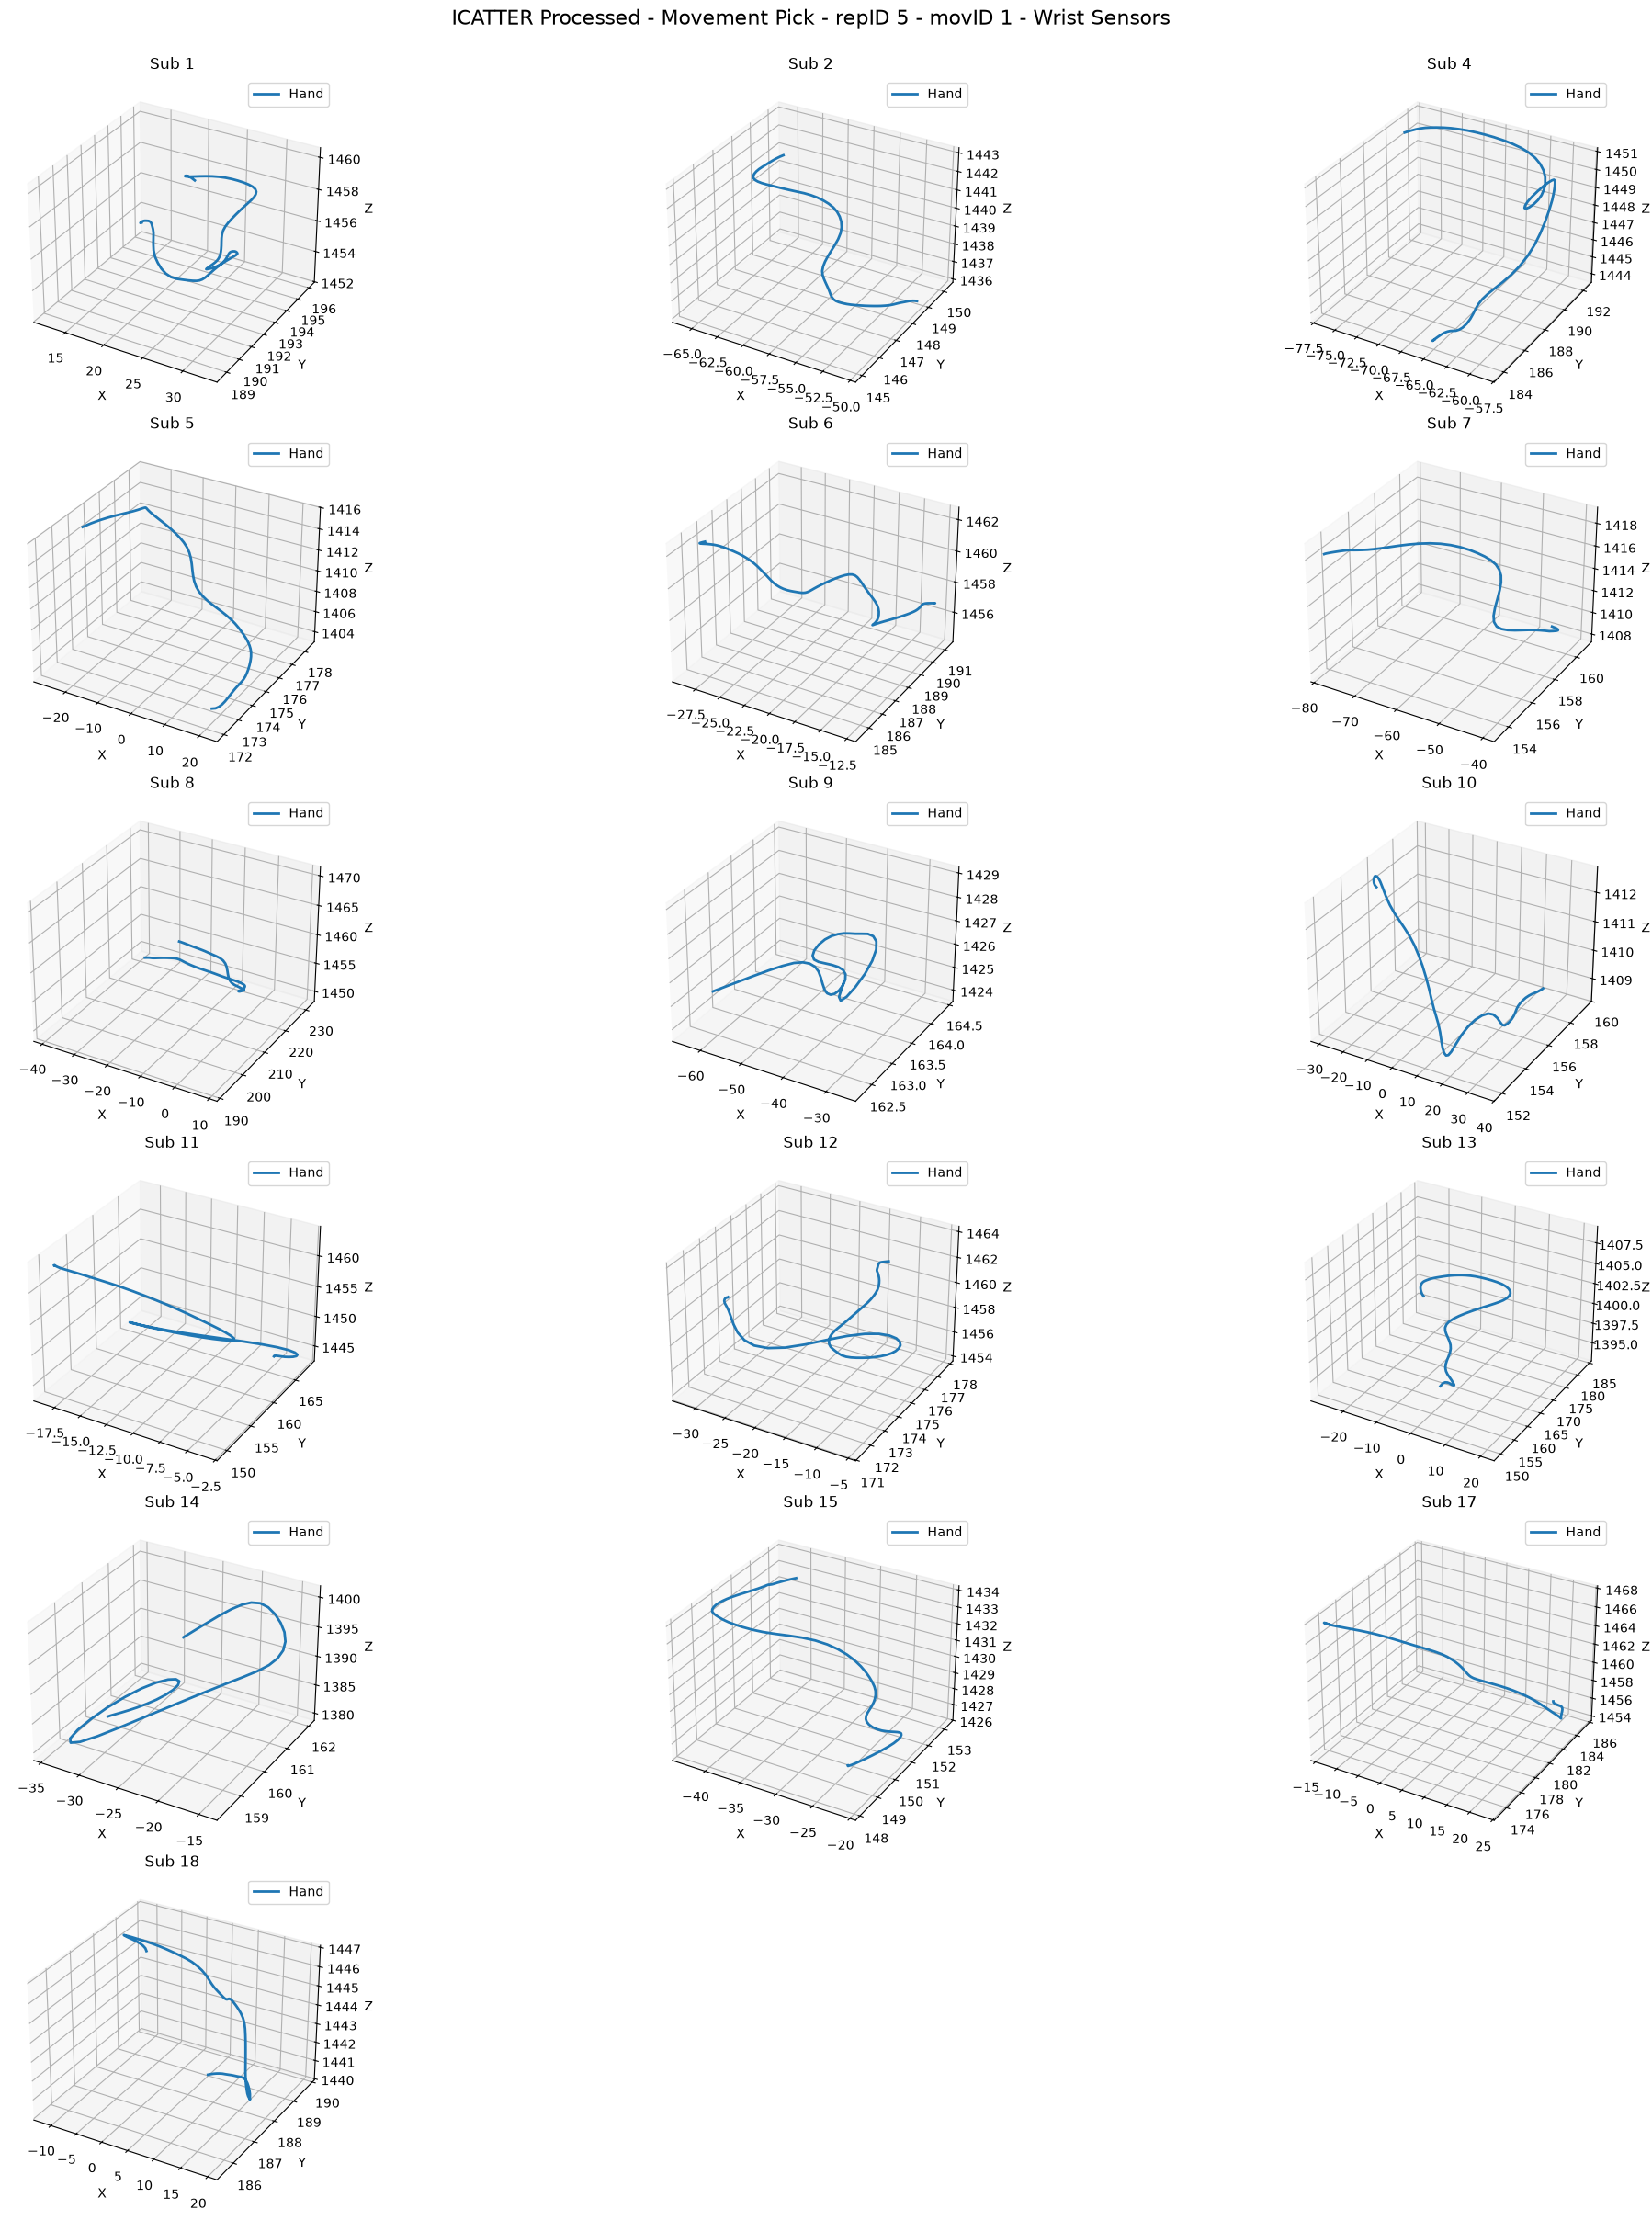

In [29]:
# Usa apenas os subjects que existem em ambas as tabelas filtradas
subs = sorted(set(df_last_RepID["sub"]).union(df_last_RepID["sub"]))

ncols = 3
nrows = math.ceil(len(subs) / ncols)

fig = plt.figure(figsize=(7 * ncols, 4 * nrows))

for i, sub in enumerate(subs, start=1):
    ax = fig.add_subplot(nrows, ncols, i, projection="3d")

    sub_hand = df_last_RepID[df_last_RepID["sub"] == sub].sort_values("step")

    if not sub_hand.empty:
        ax.plot(sub_hand["xs"], sub_hand["ys"], sub_hand["zs"],
                color="tab:blue", linewidth=2, label="Hand")

    ax.set_title(f"Sub {sub}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.legend()

# Remove eixos vazios se a grelha sobrar com espaços
for j in range(len(subs) + 1, nrows * ncols + 1):
    fig.delaxes(fig.axes[-1])

fig.suptitle(f"ICATTER Processed - Movement {MOVEMENT_TO_SHOW} - repID {REP_ID_TO_SHOW} - movID {MOV_ID_TO_SHOW} - Wrist Sensors", fontsize=16, y=1.00)
fig.tight_layout()
fig.show()